# 인증 CORS 타임아웃

**이 노트북에서 할 일**

1. 접근 토큰 검사가 401로, 시간 제한이 504로 답하는 차례를 봅니다.
2. 모든 출처를 허용한 CORS 설정이 모르는 출처에도 자격 증명을 허락하는 것을 봅니다.
3. 출처를 적은 설정과, 401에 인증 방식을 알리는 보안 도구로 고칩니다.

**준비물** — 이 노트북은 모델을 부르지 않습니다.
모델 요청은 0번이고, API 키 없이 실행합니다.
예상 비용도 0달러입니다.
실습 앱의 에이전트 그래프는 모델을 쓰지 않고, 정해 둔 말로 답합니다.
그래서 다시 실행해도 같은 값이 나와야 합니다.

요청은 시험용 클라이언트로 같은 노트북 안에서 보냅니다.
서버 프로그램과 브라우저를 쓰지 않고, 네트워크와 포트도 쓰지 않습니다.
실습 폴더의 파일을 가져오고 읽기만 하며, 쓰는 파일은 없습니다.

걸린 시간은 재지 않았습니다.
02절에서 배운 함수 하나는 도구 파일 `serve_tools.py`에서 가져옵니다.

**기준 버전** — 첫 셀에서 패키지 여섯을 설치합니다.
판은 fastapi 0.135.0, httpx 0.28.1, pydantic 2.12.5, starlette 1.6.0입니다.
패키지 langgraph 1.2.11과 langchain 1.4.0은 실습 앱 파일이 가져오는 패키지입니다.
여섯 모두 실습 폴더 잠금과 같은 판입니다.

교재 출력은 Linux의 Python 3.12.13으로 만들었습니다.
다른 판과 Windows·macOS에서는 실행하지 않았습니다.

**강의와 실습 범위** — 강의 시간에는 2~4절을 읽고, 5절과 6절의 Before·After를 함께 봅니다.
7절은 보내는 요청 하나를 바꿔 보는 실습이고, 실습 시간에 실행합니다.

실습 폴더 `labs/part7/ch30-fastapi-serving`에서 `uv sync --locked`를 실행합니다.
그다음 `notebooks/` 폴더의 이 노트북을 열고, 실습 폴더의 `.venv` 커널을 고릅니다.
첫 셀부터 순서대로 실행합니다.

## 오늘 볼 그림

![위에서 아래로 읽는 흐름도입니다. 초록 상자 POST /v1/chat 요청 머리 Origin과 Authorization에서, 회색 상자 CORS 층 CORSMiddleware 사전 요청이면 여기서 바로 답함으로 갑니다. 이어서 초록 상자 제공 함수 require_token 접근 토큰 검사, 초록 상자 처리 함수 chat 몸통 그래프를 wait_for로 기다림을 지나 노란 상자 200 답 허용 출처면 응답 머리를 덧붙임에 닿습니다. 제공 함수에서 점선이 노란 상자 401 접근 토큰이 없거나 틀림으로, 몸통에서 점선이 노란 상자 504 시간 제한 0초를 넘김으로 갈라지는 그림](attachment:07-1-요청이-처리-함수-몸통에-닿기까지.png)

위에서 아래로 읽습니다.
초록 상자는 보낸 요청과 실습 앱 파일의 함수이고, 회색 상자는 라이브러리가 맡은 CORS 층입니다.
노란 상자 셋은 노트북 2절·3절·6절의 출력이고, 점선 두 갈래는 몸통까지 가지 않거나 기다림이 끊긴 자리입니다.
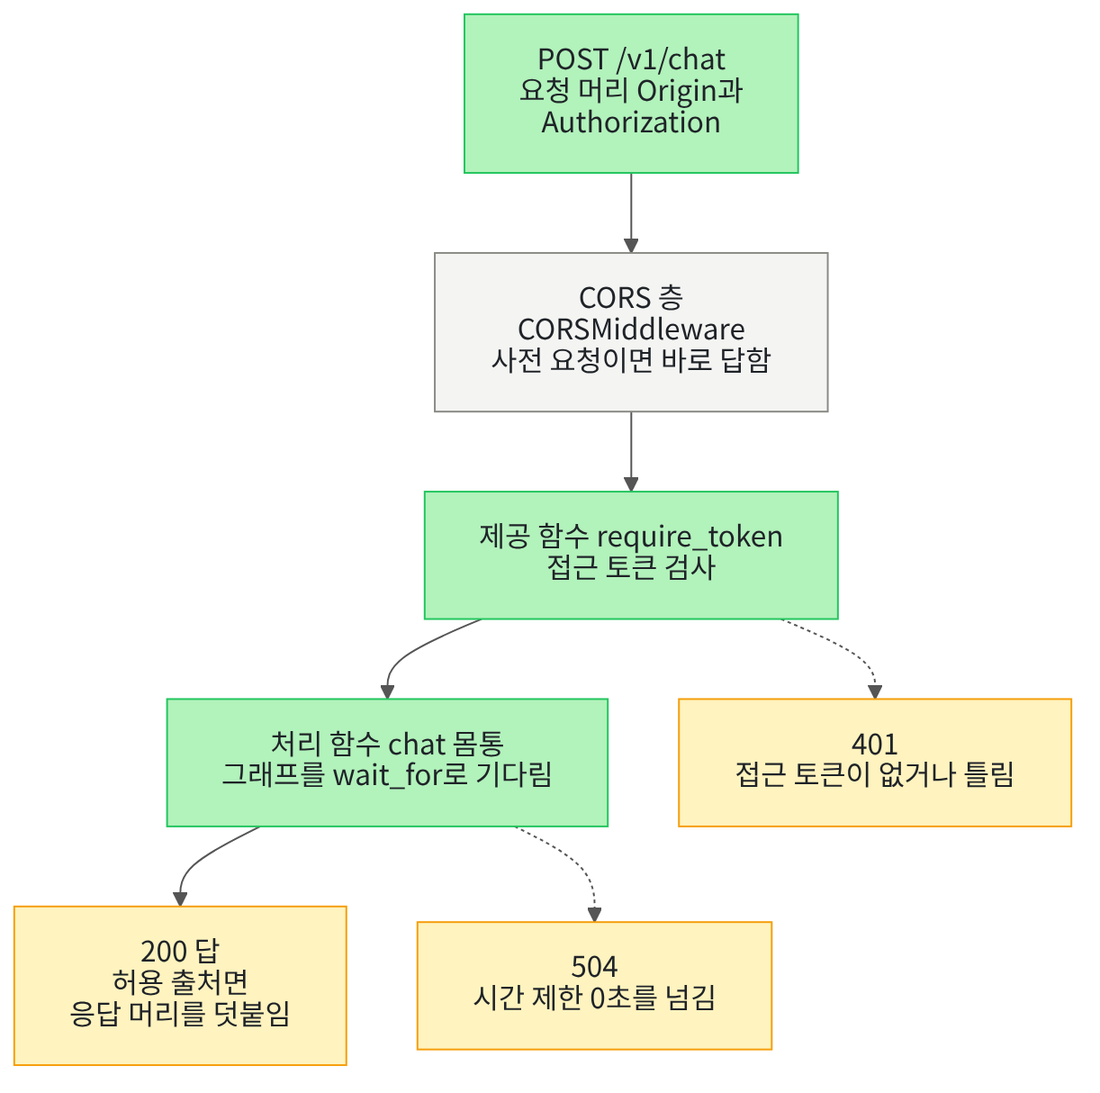

## 1. 준비

06절에서는 시간 제한을 0초로 바꾼 SSE 응답이 상태 코드 200과 오류 사건으로 오는 것을 봤습니다.
이 절은 요청이 처리 함수 몸통에 닿기 전후에 앱이 하는 검사 셋을 봅니다.
접근 토큰 검사와, 다른 출처의 요청을 다루는 CORS 설정, 시간 제한입니다.
제목의 인증은 Ch 28 03절에서 배운 말로, 요청을 보낸 쪽이 누구인지 확인하는 일입니다.
제목의 CORS는 4절에서 풀고, 제목의 타임아웃은 이 절에서 시간 제한이라고 부릅니다.

첫 셀은 패키지 여섯을 설치하고 설치된 판 번호를 출력합니다.
설치에는 몇십 초가 걸릴 수 있습니다.

In [1]:
# 이 절에서 쓰는 패키지를 설치하고 버전을 확인합니다
%pip install -q "fastapi==0.135.0" "httpx==0.28.1" "pydantic==2.12.5" "starlette==1.6.0" "langgraph==1.2.11" "langchain==1.4.0"
from importlib.metadata import version

print("fastapi:", version("fastapi"))
print("httpx:", version("httpx"))
print("pydantic:", version("pydantic"))
print("starlette:", version("starlette"))
print("langgraph:", version("langgraph"))
print("langchain:", version("langchain"))

Note: you may need to restart the kernel to use updated packages.


fastapi: 0.135.0
httpx: 0.28.1
pydantic: 2.12.5
starlette: 1.6.0
langgraph: 1.2.11
langchain: 1.4.0


**결과 읽기** — 출력 줄 `fastapi: 0.135.0`과 `starlette: 1.6.0`이 보입니다.
여섯 모두 실습 폴더 잠금과 같은 판이고, 06절과 같은 목록입니다.
CORS 설정을 맡는 클래스는 패키지 starlette에 있고, 패키지 fastapi가 같은 이름으로 내어 줍니다.
이 절은 모델 객체를 만들지 않아, API 키를 확인하는 셀도 없습니다.

다음 셀은 이 절에서 쓸 이름을 가져옵니다.
클래스 `CORSMiddleware`는 CORS 설정을, 클래스 `HTTPBearer`는 접근 토큰 읽기를 맡습니다.
마지막 가져오기 줄은 02절에서 배운 함수를 도구 파일에서 가져옵니다.

In [2]:
# 이 절에서 쓸 이름을 가져옵니다(os와 typing은 Python에 들어 있는 모듈입니다)
import os
from typing import Annotated
from fastapi import Depends, FastAPI
from fastapi.middleware.cors import CORSMiddleware
from fastapi.security import HTTPBearer
from fastapi.testclient import TestClient
# 02절에서 배운 함수는 도구 파일에서 가져옵니다
from serve_tools import zero_timeout

print("가져온 이름:", "Annotated, Depends, FastAPI, CORSMiddleware, HTTPBearer, TestClient")
print("도구 파일에서 가져온 함수:", "zero_timeout")

가져온 이름: Annotated, Depends, FastAPI, CORSMiddleware, HTTPBearer, TestClient
도구 파일에서 가져온 함수: zero_timeout


**결과 읽기** — 출력 줄 `도구 파일에서 가져온 함수: zero_timeout`이 보입니다.
함수 `zero_timeout`은 02절에서 배운, 0초를 내놓는 재정의 함수입니다.
06절이 도구 파일로 옮긴 판을 그대로 가져왔습니다.
도구 파일에는 다른 함수도 있지만, 이 절에서는 쓰지 않습니다.

앞에서 배운 함수는 `serve_tools.py`에 모아 두었습니다.
파일을 열면 코드를 볼 수 있습니다.
노트북과 같은 폴더(`notebooks/`)에 있는 파일입니다.
커널이 `notebooks/` 폴더에서 시작해야 이 파일을 가져올 수 있습니다.
교재 출력을 만든 실행 도구는 이 폴더를 따로 알려 주어, 다른 자리에서 시작해도 가져오기가 되었습니다.

다음 셀은 01절 2절과 같은 파일 위치 셀로, 후보 셋 가운데 실습 폴더를 고릅니다.

In [3]:
# 노트북을 연 자리에서 본 실습 폴더의 위치를 후보 셋 가운데에서 고릅니다
candidates = ["..", ".", "labs/part7/ch30-fastapi-serving"]
lab_path = None
for candidate in candidates:
    if os.path.exists(candidate + "/agent_service/schemas.py"):
        lab_path = candidate
        break
print("실습 폴더를 찾았는가:", lab_path is not None)
assert lab_path is not None, "notebooks 폴더나 실습 폴더 맨 위에서 노트북을 열어 주세요."

실습 폴더를 찾았는가: True


**결과 읽기** — 출력 줄 `실습 폴더를 찾았는가: True`가 보입니다.
고른 후보는 연 자리마다 달라서 출력하지 않습니다.
실습 폴더 맨 위에서 연 커널은 이 안내를 보기 전에, 앞 셀의 도구 파일 가져오기에서 먼저 멈춥니다.

다음 셀은 06절처럼 작업 폴더를 실습 폴더로 옮긴 뒤 이름을 가져옵니다.
앱 파일에서 앱 객체 `app`과 처리 함수 `chat`, 시간 제한 제공 함수 `get_timeout`을 가져옵니다.
처리 함수 `chat`은 5절에서 새 앱 객체에 다시 잇습니다.

In [4]:
# 작업 폴더를 실습 폴더로 옮기고, 앱 객체·처리 함수 chat·시간 제한 제공 함수를 가져옵니다
os.chdir(lab_path)
from agent_service.app import app, chat, get_timeout
print("가져온 앱 객체의 종류:", type(app).__name__)
print("가져온 처리 함수:", chat.__name__)
print("재정의 딕셔너리의 키 수:", len(app.dependency_overrides))

가져온 앱 객체의 종류: FastAPI
가져온 처리 함수: chat
재정의 딕셔너리의 키 수: 0


**결과 읽기** — 출력 줄 `가져온 앱 객체의 종류: FastAPI`와 `가져온 처리 함수: chat`이 보입니다.
출력 줄 `재정의 딕셔너리의 키 수: 0`은 아직 바꿔 낀 제공 함수가 없다는 뜻입니다.

## 2. 접근 토큰 검사

02절에서는 접근 토큰 없이 보낸 질문이 401을 받는 것을 한 번 봤습니다.
이 절에서는 그 검사를 하는 줄을 읽습니다.
다음 셀은 앱 파일에서 제공 함수 `require_token`의 줄을 출력합니다.

In [5]:
# 앱 파일을 글로 읽어, 접근 토큰을 검사하는 제공 함수 require_token의 56~60행을 출력합니다
first_line = 56
last_line = 60
with open("agent_service/app.py", encoding="utf-8") as app_file:
    app_lines = app_file.read().splitlines()
print("줄 번호 | 줄")
for index in range(first_line - 1, last_line):
    print(index + 1, "|", app_lines[index])

줄 번호 | 줄
56 | async def require_token(authorization: Annotated[str | None, Header()] = None) -> str:
57 |     expected = os.getenv("DEMO_API_TOKEN", "local-demo-token")
58 |     if authorization != f"Bearer {expected}":
59 |         raise HTTPException(status_code=401, detail="인증 정보가 올바르지 않습니다")
60 |     return expected


**결과 읽기** — 라벨 줄 아래 56행의 `Header()`는 요청 머리 `Authorization`의 값을 매개변수에 넣으라는 뜻입니다.
57행은 환경 변수 `DEMO_API_TOKEN`이 없으면 교재용 값 `local-demo-token`을 씁니다.
58행은 받은 값이 `Bearer`와 공백, 교재용 값을 이은 글과 다르면 59행에서 401로 멈춥니다.
58행의 f-string은 이 과정의 노트북에서 쓰지 않는 모양이라, 뜻만 봅니다.
56행의 `str | None`과 `= None`, 내놓는 값 힌트 `-> str`은 06절에서 본 모양입니다.

접근 토큰은 Ch 28 03절의 말로, 요청에 실어 보내 누구인지 알리는 글입니다.
값 앞의 `Bearer`는 접근 토큰을 요청 머리에 그대로 싣는 인증 방식의 이름입니다.
다음 셀은 요청 머리 셋으로 같은 질문을 보내, 상태 코드와 응답 본문을 봅니다.
접근 토큰이 없는 요청, 틀린 요청, 맞는 요청입니다.

In [6]:
# 요청 머리 셋으로 같은 질문을 보내, 접근 토큰 검사의 상태 코드와 응답 본문을 봅니다
client = TestClient(app)
auth_headers = {"Authorization": "Bearer local-demo-token"}
question_body = {"question": "반납 기한을 알려 주세요", "thread_id": "auth-1"}
print("요청 머리 | 상태 코드 | 응답 본문")
for sent_headers in [{}, {"Authorization": "Bearer wrong-token"}, auth_headers]:
    auth_response = client.post("/v1/chat", json=question_body, headers=sent_headers)
    print(sent_headers, "|", auth_response.status_code, "|", auth_response.json())

요청 머리 | 상태 코드 | 응답 본문
{} | 401 | {'detail': '인증 정보가 올바르지 않습니다'}
{'Authorization': 'Bearer wrong-token'} | 401 | {'detail': '인증 정보가 올바르지 않습니다'}
{'Authorization': 'Bearer local-demo-token'} | 200 | {'answer': '질문을 확인했습니다: 반납 기한을 알려 주세요', 'thread_id': 'auth-1'}


**결과 읽기** — 라벨 줄 아래 첫 두 줄은 상태 코드 `401`과 `{'detail': '인증 정보가 올바르지 않습니다'}`입니다.
접근 토큰이 없을 때와 틀렸을 때 같은 응답이 왔습니다.
셋째 줄은 `200`이고, 응답 본문에 답 `질문을 확인했습니다: 반납 기한을 알려 주세요`가 있습니다.

06절에서 본 것처럼, 라이브러리는 제공 함수를 처리 함수보다 먼저 부릅니다.
그래서 접근 토큰이 틀리면 처리 함수의 몸통은 실행되지 않습니다.
그런지는 3절의 출력으로 확인합니다.

## 3. 시간 제한

02절에서 본 것처럼, 처리 함수 `chat`은 에이전트 그래프를 `asyncio.wait_for`로 기다립니다.
정한 초 안에 끝나지 않으면, 앱 78~82행이 오류 `TimeoutError`를 받아 상태 코드 504로 답합니다.
다음 셀은 시간 제한을 0초로 재정의하고, 접근 토큰이 있는 요청과 없는 요청을 보냅니다.
재정의 함수 `zero_timeout`은 도구 파일에서 가져왔고, 재정의는 같은 셀 안에서 비웁니다.

실행 전에 예상해 봅니다.
접근 토큰이 없는 요청도 504를 받을까요?

In [7]:
# 시간 제한을 0초로 재정의해 접근 토큰이 있는 요청과 없는 요청을 보내고, 같은 셀에서 재정의를 비웁니다
app.dependency_overrides[get_timeout] = zero_timeout
timed_response = client.post("/v1/chat", json=question_body, headers=auth_headers)
no_token_response = client.post("/v1/chat", json=question_body)
app.dependency_overrides.clear()
print("접근 토큰이 있는 요청:", timed_response.status_code, timed_response.json())
print("접근 토큰이 없는 요청:", no_token_response.status_code, no_token_response.json())
print("비운 뒤 재정의 딕셔너리의 키 수:", len(app.dependency_overrides))

접근 토큰이 있는 요청: 504 {'detail': 'Agent 응답 시간이 초과되었습니다'}
접근 토큰이 없는 요청: 401 {'detail': '인증 정보가 올바르지 않습니다'}
비운 뒤 재정의 딕셔너리의 키 수: 0


**결과 읽기** — 출력 줄 `접근 토큰이 있는 요청: 504 {'detail': 'Agent 응답 시간이 초과되었습니다'}`가 보입니다.
접근 토큰이 없는 요청은 시간 제한이 0초인데도 `401`을 받았습니다.
접근 토큰 검사가 몸통보다 먼저 멈춰, 그래프를 기다리는 줄까지 가지 않았다는 뜻입니다.
출력 줄 `비운 뒤 재정의 딕셔너리의 키 수: 0`으로, 재정의가 남지 않은 것도 확인했습니다.

이 앱의 `/v1/chat`은 그래프를 다 기다린 뒤에 응답을 시작합니다.
그래서 기다림이 끊기면 상태 코드를 504로 정할 수 있습니다.
06절의 SSE 응답은 상태 코드 200을 먼저 보내, 같은 0초에도 오류 사건으로 알렸습니다.

## 4. CORS와 사전 요청

제목의 CORS는 Cross-Origin Resource Sharing의 머리글자입니다.
다른 출처의 웹 화면이 보낸 요청에, 그 응답을 화면의 스크립트가 읽어도 되는지 서버가 응답 머리로 알리는 규칙입니다.
응답을 스크립트에 넘길지는 브라우저가 그 응답 머리를 보고 정합니다.
이웃이 우리 집 우편물을 받아 가려 하면, 경비실이 적힌 받는 사람을 보고 내줄지 정하는 것과 같습니다.
이 앱에서는 앱 파일 19~26행이 CORS 설정입니다.

출처(origin)는 주소 앞부분의 방식(http·https), 호스트 이름, 포트 번호를 합친 것입니다.
같은 아파트라도 동과 호수가 다르면 다른 집인 것과 같습니다.
주소 `http://localhost:5173`과 `https://evil.example`은 서로 다른 출처입니다.
다음 셀은 앱 파일에서 CORS 설정을 적은 줄을 출력합니다.

In [8]:
# 앱 파일에서 CORS 설정을 적은 19~26행을 출력합니다(2절에서 읽어 둔 줄 목록을 씁니다)
first_line = 19
last_line = 26
print("줄 번호 | 줄")
for index in range(first_line - 1, last_line):
    print(index + 1, "|", app_lines[index])

줄 번호 | 줄
19 | app.add_middleware(
20 |     CORSMiddleware,
21 |     allow_origins=["http://localhost:5173"],
22 |     allow_credentials=True,
23 |     allow_methods=["GET", "POST"],
24 |     allow_headers=["Authorization", "Content-Type", "Last-Event-ID"],
25 |     expose_headers=["X-Request-ID"],
26 | )


**결과 읽기** — 라벨 줄 아래 21행은 허용 출처를 `http://localhost:5173` 하나로 적었습니다.
허용 출처는 응답을 읽어도 된다고 서버가 허락한 출처입니다.
22행 `allow_credentials=True`는 자격 증명을 실은 요청도 허락한다는 뜻입니다.
23행과 24행은 허락할 요청 방식과 요청 머리를 이름으로 적었습니다.
25행의 `expose_headers`는 스크립트가 읽어도 되는 응답 머리 이름이고, 이 절에서는 쓰지 않습니다.

자격 증명(credentials)은 쿠키와 인증 정보처럼, 요청한 사람이 누구인지 알리는 값입니다.
가게에서 회원 카드를 내밀면, 가게가 누구인지 알아보는 것과 같습니다.
MDN 문서는 자격 증명을 실은 요청이면, 허용 출처 응답 머리가 없는 응답을 브라우저가 버린다고 적습니다.
19행의 메서드 `add_middleware`는 이 설정을 맡은 층을 앱 객체 앞에 끼워 넣습니다.

다음 셀은 응답 머리에서 이름 하나의 값을 꺼내는 함수를 정의합니다.
CORS 응답 머리는 조건에 따라 붙지 않을 수 있어, 없으면 `None`을 내놓게 합니다.

In [9]:
# 응답 머리에서 이름이 name인 칸의 값을 내놓습니다(그런 칸이 없으면 None)
def header_or_none(response, name):
    if name in response.headers:
        return response.headers[name]
    return None

**결과 읽기** — 정의 셀이라 출력이 없습니다.
응답 머리 이름은 대문자와 소문자를 가리지 않아, 소문자로 적어도 찾습니다.

사전 요청(preflight request)은 실제 요청 전에 브라우저가 먼저 보내, 허락을 묻는 요청입니다.
큰 짐을 부치기 전에, 받는 쪽에 받을 수 있는지 전화로 먼저 묻는 것과 같습니다.
요청 방식은 OPTIONS이고, 요청 머리 `Origin`에 출처를, `Access-Control-Request-Method`에 보낼 요청 방식을 적습니다.
MDN 문서에 따르면, 요청 머리 `Authorization`이나 본문 종류 `application/json`을 실으면 사전 요청이 먼저 갑니다.
다음 셀은 허용 출처에서 온 것처럼 사전 요청을 보내고, CORS 응답 머리를 봅니다.

In [10]:
# 허용 출처 http://localhost:5173에서 온 것처럼 사전 요청을 보내고, CORS 응답 머리를 봅니다
ok_preflight_headers = {"Origin": "http://localhost:5173", "Access-Control-Request-Method": "POST",
                        "Access-Control-Request-Headers": "Authorization, Content-Type"}
ok_preflight = client.options("/v1/chat", headers=ok_preflight_headers)
print("상태 코드:", ok_preflight.status_code)
print("허용 출처:", header_or_none(ok_preflight, "access-control-allow-origin"))
print("자격 증명 허용:", header_or_none(ok_preflight, "access-control-allow-credentials"))
print("허용 요청 방식:", header_or_none(ok_preflight, "access-control-allow-methods"))
print("허용 요청 머리:", header_or_none(ok_preflight, "access-control-allow-headers"))

상태 코드: 200
허용 출처: http://localhost:5173
자격 증명 허용: true
허용 요청 방식: GET, POST
허용 요청 머리: Accept, Accept-Language, Authorization, Content-Language, Content-Type, Last-Event-ID


**결과 읽기** — 출력 줄 `상태 코드: 200`과 `허용 출처: http://localhost:5173`이 보입니다.
출력 줄 `자격 증명 허용: true`도 보입니다.
허용 요청 방식은 `GET, POST`이고, 허용 요청 머리에는 `Authorization`과 `Content-Type`이 들어 있습니다.
허용 요청 머리에는 설정에 적지 않은 `Accept` 같은 이름도 있습니다.
설치판 starlette `cors.py` 12행이 늘 허락하는 요청 머리 넷을 설정에 더하기 때문입니다.

이 응답은 처리 함수까지 가지 않았습니다.
설치판 `cors.py` 91~94행은 사전 요청이면 CORS 층이 바로 답하고, 앱으로 넘기지 않습니다.
시험용 클라이언트는 브라우저가 아니라서, 이 응답 머리를 보고 요청을 막지 않습니다.
그래서 이 절은 응답 머리를 출력해 읽고, 브라우저가 막는 모양은 실행하지 않았습니다.

## 5. 모든 출처를 허용한 설정과 머리 없는 401 (Before)

설정의 세 칸을 모두 `"*"`로 두면, 모든 출처와 요청 방식, 요청 머리를 허락한다는 뜻입니다.
여기에 `allow_credentials=True`까지 더하면 어떻게 될까요?
FastAPI 문서는 자격 증명을 허락하면 세 칸 가운데 어느 것도 `["*"]`로 둘 수 없다고 적습니다.
다음 셀은 그 설정으로 새 앱 객체를 만들고, 실습 앱의 처리 함수 `chat`을 잇습니다.
메서드 `add_api_route`는 05절에서 본, 처리 함수를 요청 방식과 요청 주소에 잇는 메서드입니다.

In [11]:
# 허용 출처·요청 방식·요청 머리를 모두 "*"로 두고 자격 증명을 허락한 새 앱 객체에, 처리 함수 chat을 잇습니다
wide_app = FastAPI()
wide_app.add_middleware(CORSMiddleware, allow_origins=["*"], allow_credentials=True,
                        allow_methods=["*"], allow_headers=["*"])
wide_app.add_api_route("/v1/chat", chat, methods=["POST"])
wide_client = TestClient(wide_app)
print("새 앱 객체에 이은 요청 주소:", wide_app.routes[-1].path)

새 앱 객체에 이은 요청 주소: /v1/chat


**결과 읽기** — 출력 줄 `새 앱 객체에 이은 요청 주소: /v1/chat`이 보입니다.
설치판 starlette 1.6.0은 이 설정에 오류를 내지 않고 앱을 만들었습니다.
처리 함수는 실습 앱과 같아, 접근 토큰 검사와 시간 제한도 그대로 따라옵니다.

다음 셀은 모르는 출처 `https://evil.example`에서 온 것처럼 사전 요청을 보냅니다.
4절과 같은 요청 머리에서 출처만 바꿉니다.
실행 전에 예상해 봅니다.
모르는 출처에도 허용 출처 응답 머리가 올까요?

In [12]:
# 모르는 출처 https://evil.example에서 온 것처럼 사전 요청을 보내고, CORS 응답 머리를 봅니다
evil_preflight_headers = {"Origin": "https://evil.example", "Access-Control-Request-Method": "POST",
                          "Access-Control-Request-Headers": "Authorization, Content-Type"}
wide_preflight = wide_client.options("/v1/chat", headers=evil_preflight_headers)
print("상태 코드:", wide_preflight.status_code)
print("허용 출처:", header_or_none(wide_preflight, "access-control-allow-origin"))
print("자격 증명 허용:", header_or_none(wide_preflight, "access-control-allow-credentials"))

상태 코드: 200
허용 출처: https://evil.example
자격 증명 허용: true


**결과 읽기** — 출력 줄 `상태 코드: 200`과 `허용 출처: https://evil.example`이 보입니다.
출력 줄 `자격 증명 허용: true`도 보입니다.
서버는 요청 머리에 온 출처를 그대로 허용 출처 응답 머리에 적어 보냈습니다.
브라우저가 보기에는 이 출처를 이름으로 허락한 응답입니다.

설치판 `cors.py` 37행은 모든 출처와 자격 증명을 함께 허락하면, 출처를 이름으로 적는 쪽을 고릅니다.
116~120행은 그때 요청에 온 출처를 그대로 응답 머리에 씁니다.
MDN 문서는 자격 증명을 실은 요청에는 `"*"` 대신 출처를 이름으로 적으라고 적습니다.
설치판은 받은 출처를 옮겨 적어 그 조건을 맞추고, 그래서 아무 출처나 허락합니다.

다음 셀은 같은 모르는 출처에서 접근 토큰을 실은 POST를 보냅니다.
사전 요청이 통과하면 브라우저가 이어서 보내는 실제 요청입니다.

In [13]:
# 같은 모르는 출처에서 접근 토큰을 실은 POST를 보내고, 응답 본문과 CORS 응답 머리를 봅니다
evil_headers = {"Origin": "https://evil.example", "Authorization": "Bearer local-demo-token"}
wide_post = wide_client.post("/v1/chat", json=question_body, headers=evil_headers)
print("상태 코드:", wide_post.status_code)
print("응답 본문:", wide_post.json())
print("허용 출처:", header_or_none(wide_post, "access-control-allow-origin"))
print("자격 증명 허용:", header_or_none(wide_post, "access-control-allow-credentials"))

상태 코드: 200
응답 본문: {'answer': '질문을 확인했습니다: 반납 기한을 알려 주세요', 'thread_id': 'auth-1'}
허용 출처: https://evil.example
자격 증명 허용: true


**결과 읽기** — 출력 줄 `상태 코드: 200`과 `허용 출처: https://evil.example`이 보입니다.
응답 본문에는 답이 있고, 출력 줄 `자격 증명 허용: true`도 보입니다.
설치판 `cors.py` 166~168행이 보통 요청에도 받은 출처를 그대로 적었습니다.
모르는 출처의 웹 화면도 자격 증명을 실은 요청의 답을 읽게 된다는 뜻입니다.
이것이 이 절의 첫째 Before 결함입니다.

이 앱은 접근 토큰을 스크립트가 요청 머리에 직접 싣습니다.
모르는 웹 화면이 이 값을 실으려면, 먼저 그 값을 알아야 합니다.
설정 `allow_credentials`로 문제가 되는 것은 브라우저가 스스로 붙이는 쿠키 같은 값입니다.
쿠키로 사용자를 알아보는 앱이라면, 사용자가 연 다른 웹 화면이 그 답을 읽을 수 있습니다.
브라우저에서는 이 장면을 실행하지 않았습니다.

둘째 결함은 접근 토큰 검사의 응답에 있습니다.
Ch 28 03절 노트북 6절의 서버는 401과 함께 응답 머리 `WWW-Authenticate`의 값 `Bearer`를 보냈습니다.
그 값은 요청 머리에 접근 토큰을 실어 보내라는 표시였습니다.
HTTP 표준 문서 RFC 9110은 401 응답에 이 응답 머리를 반드시 담으라고 적습니다.
다음 셀은 실습 앱이 보낸 401 응답에 이 응답 머리가 있는지 봅니다.

In [14]:
# 실습 앱이 보낸 401 응답에, 인증 방식을 알리는 응답 머리 WWW-Authenticate가 있는지 봅니다
missing_response = client.post("/v1/chat", json=question_body)
print("상태 코드:", missing_response.status_code)
print("WWW-Authenticate:", header_or_none(missing_response, "www-authenticate"))
print("응답 머리 이름:", list(missing_response.headers))

상태 코드: 401
WWW-Authenticate: None
응답 머리 이름: ['content-length', 'content-type']


**결과 읽기** — 출력 줄 `상태 코드: 401`과 `WWW-Authenticate: None`이 보입니다.
출력 줄 `응답 머리 이름: ['content-length', 'content-type']`에서, 응답 머리는 둘뿐입니다.
앱 59행의 오류에는 응답 머리를 적는 인자가 없기 때문입니다.
받는 쪽은 401을 받고도, 어떤 방식으로 접근 토큰을 보내야 하는지 응답에서 찾지 못합니다.
이것이 둘째 Before 결함입니다.

## 6. 출처를 적은 설정과 HTTPBearer (After)

첫째 After는 실습 앱의 설정입니다.
4절에서 본 것처럼 실습 앱은 허용 출처와 요청 방식, 요청 머리를 모두 이름으로 적었습니다.
다음 셀은 5절과 같은 모르는 출처의 사전 요청을 실습 앱에 보냅니다.

In [15]:
# 출처를 적은 실습 앱에 5절과 같은 모르는 출처의 사전 요청을 보내고, 상태 코드와 CORS 응답 머리를 봅니다
lab_preflight = client.options("/v1/chat", headers=evil_preflight_headers)
print("상태 코드:", lab_preflight.status_code)
print("응답 본문:", lab_preflight.text)
print("허용 출처:", header_or_none(lab_preflight, "access-control-allow-origin"))
print("자격 증명 허용:", header_or_none(lab_preflight, "access-control-allow-credentials"))

상태 코드: 400
응답 본문: Disallowed CORS origin
허용 출처: None
자격 증명 허용: true


**결과 읽기** — 출력 줄 `상태 코드: 400`과 `응답 본문: Disallowed CORS origin`이 보입니다.
출력 줄 `허용 출처: None`으로, 허용 출처 응답 머리가 붙지 않았습니다.
설치판 `cors.py` 116~122행은 허락하지 않은 출처를 실패 목록에 넣고, 146~148행이 400으로 답합니다.
출력 줄 `자격 증명 허용: true`는 설정 값이 그대로 붙은 것입니다.
허용 출처 응답 머리가 없으니, MDN 문서대로라면 브라우저는 이 응답을 버립니다.

같은 파일 143~145행의 주석은 400이 꼭 필요하지는 않다고 적습니다.
CORS 규칙을 지키는 쪽은 브라우저이고, 400은 알아보기 좋게 보내는 값이라는 뜻입니다.

다음 셀은 허용 출처에서 접근 토큰을 실은 POST를 실습 앱에 보냅니다.
출처를 적은 설정이 허용 출처의 요청까지 막지 않는지 봅니다.

In [16]:
# 허용 출처에서 접근 토큰을 실은 POST를 실습 앱에 보내고, 응답 본문과 허용 출처 응답 머리를 봅니다
ok_headers = {"Origin": "http://localhost:5173", "Authorization": "Bearer local-demo-token"}
ok_post = client.post("/v1/chat", json=question_body, headers=ok_headers)
print("상태 코드:", ok_post.status_code)
print("응답 본문:", ok_post.json())
print("허용 출처:", header_or_none(ok_post, "access-control-allow-origin"))

상태 코드: 200
응답 본문: {'answer': '질문을 확인했습니다: 반납 기한을 알려 주세요', 'thread_id': 'auth-1'}
허용 출처: http://localhost:5173


**결과 읽기** — 출력 줄 `상태 코드: 200`과 `허용 출처: http://localhost:5173`이 보입니다.
응답 본문에도 2절과 같은 답이 왔습니다.
설정에 적은 출처의 웹 화면은 전처럼 답을 읽을 수 있습니다.

둘째 After는 FastAPI가 주는 보안 도구 클래스 `HTTPBearer`입니다.
이 클래스로 만든 객체를 의존성에 적으면, 요청 머리 `Authorization`에서 방식 이름과 글을 읽어 줍니다.
실습 앱을 이 클래스로 바꾸면 응답 문서가 달라져서, 이 절은 노트북에 새 앱 객체를 만들어 봅니다.
다음 셀은 보안 객체와, 02절처럼 표시 `Annotated`로 만든 의존성 이름을 만듭니다.

In [17]:
# Bearer 방식의 접근 토큰을 읽는 보안 객체와 의존성 이름, 그 객체를 쓸 새 앱 객체를 만듭니다
bearer = HTTPBearer()
BearerDep = Annotated[object, Depends(bearer)]
bearer_app = FastAPI()
print("보안 객체의 종류:", type(bearer).__name__)

보안 객체의 종류: HTTPBearer


**결과 읽기** — 출력 줄 `보안 객체의 종류: HTTPBearer`가 보입니다.
의존성 이름 `BearerDep`의 둘째 자리에는, 제공 함수 대신 이 객체를 넣었습니다.
라이브러리는 요청마다 이 객체를 불러, 요청 머리를 읽은 값을 매개변수에 넣습니다.

다음 셀은 새 앱 객체에 처리 함수를 잇습니다.
데코레이터 줄은 01절처럼 아래 함수를 요청 방식 GET과 요청 주소 `/whoami`에 잇습니다.
처리 함수는 읽은 값의 칸 `scheme`에 든 방식 이름만 내놓습니다.

In [18]:
# 새 앱 객체의 GET /whoami에 처리 함수를 잇습니다 — 보안 객체가 읽은 값에서 방식 이름만 내놓습니다
@bearer_app.get("/whoami")
async def whoami(cred: BearerDep):
    return {"scheme": cred.scheme}

**결과 읽기** — 정의 셀이라 출력이 없습니다.
매개변수 `cred`에는 칸 `scheme`과 `credentials`가 있는 값이 들어옵니다.
칸 `credentials`는 접근 토큰 글이라, 이 처리 함수는 내놓지 않습니다.

다음 셀은 요청 머리 셋으로 이 처리 함수를 부릅니다.
머리 없음, 다른 인증 방식 `Basic`, 방식 `Bearer`에 틀린 글 `abc`를 적은 요청입니다.
실행 전에 예상해 봅니다.
틀린 글 `abc`는 몇 번 상태 코드를 받을까요?

In [19]:
# 요청 머리 셋으로 GET /whoami를 보내, 상태 코드와 응답 머리 WWW-Authenticate를 봅니다
bearer_client = TestClient(bearer_app)
print("요청 머리 | 상태 코드 | WWW-Authenticate | 응답 본문")
for sent_headers in [{}, {"Authorization": "Basic abc"}, {"Authorization": "Bearer abc"}]:
    bearer_response = bearer_client.get("/whoami", headers=sent_headers)
    challenge = header_or_none(bearer_response, "www-authenticate")
    print(sent_headers, "|", bearer_response.status_code, "|", challenge, "|", bearer_response.json())

요청 머리 | 상태 코드 | WWW-Authenticate | 응답 본문
{} | 401 | Bearer | {'detail': 'Not authenticated'}
{'Authorization': 'Basic abc'} | 401 | Bearer | {'detail': 'Not authenticated'}
{'Authorization': 'Bearer abc'} | 200 | None | {'scheme': 'Bearer'}


**결과 읽기** — 라벨 줄 아래 첫 두 줄은 `401 | Bearer | {'detail': 'Not authenticated'}`로 끝납니다.
머리가 없을 때와 방식이 `Basic`일 때 모두, 401과 함께 응답 머리 `WWW-Authenticate`의 값 `Bearer`가 왔습니다.
Ch 28 03절의 401과 같은 모양입니다.
셋째 줄은 `200 | None | {'scheme': 'Bearer'}`입니다.
보안 객체는 방식 이름과 글이 있는지만 보고, 접근 토큰 글이 맞는지는 보지 않습니다.

설치판 fastapi `security/http.py` 303~316행은 요청 머리를 방식 이름과 글로 나누고, 방식만 견줍니다.
84~92행은 401을 만들 때 응답 머리 `WWW-Authenticate`를 함께 적습니다.
그래서 글을 견주는 일은 실습 앱 58행처럼 우리 코드가 맡아야 합니다.
틀린 글에 보낼 401에도 같은 응답 머리를 적어야 하고, 이 노트북에서는 그 줄을 실행하지 않았습니다.

다음 셀은 두 앱 객체가 만든 응답 문서(OpenAPI)에서, 보안 방식을 적는 칸을 봅니다.
응답 문서는 앱 객체가 요청 주소와 입력 형식을 모아 적은 문서이고, 08절에서 자세히 봅니다.

In [20]:
# 두 앱 객체가 만든 응답 문서(OpenAPI)에서, 보안 방식 칸과 접근 토큰을 받는 자리를 봅니다
lab_components = app.openapi()["components"]
bearer_components = bearer_app.openapi()["components"]
lab_parameters = app.openapi()["paths"]["/v1/chat"]["post"]["parameters"]
print("실습 앱 응답 문서에 보안 방식 칸이 있는가:", "securitySchemes" in lab_components)
print("새 앱 응답 문서의 보안 방식:", bearer_components["securitySchemes"])
print("실습 앱 /v1/chat의 매개변수 이름과 자리:", lab_parameters[0]["name"], lab_parameters[0]["in"])

실습 앱 응답 문서에 보안 방식 칸이 있는가: False
새 앱 응답 문서의 보안 방식: {'HTTPBearer': {'type': 'http', 'scheme': 'bearer'}}
실습 앱 /v1/chat의 매개변수 이름과 자리: authorization header


**결과 읽기** — 출력 줄 `실습 앱 응답 문서에 보안 방식 칸이 있는가: False`가 보입니다.
새 앱 응답 문서의 보안 방식은 `{'HTTPBearer': {'type': 'http', 'scheme': 'bearer'}}`입니다.
실습 앱은 접근 토큰을 요청 머리 매개변수 `authorization`으로 받아, 응답 문서에도 매개변수로만 적힙니다.
실습 앱을 보안 객체로 바꾸면 응답 문서가 바뀌고, 08절이 쓰는 문서 파일과 어긋납니다.
그래서 이 절은 실습 앱을 고치지 않았습니다.

## 7. 값 바꿔 보기: 사전 요청 없이 보낸 POST

값 하나만 바꿔 봅니다.
6절 첫 셀은 모르는 출처의 사전 요청을 실습 앱에 보냈습니다.
이번에는 사전 요청 없이, 5절의 POST를 그대로 실습 앱에 보냅니다.
브라우저가 아닌 프로그램은 사전 요청을 보내지 않고 바로 요청할 수 있습니다.

실행 전에 예상해 봅니다.
출처를 적은 실습 앱은 이 요청에 답을 만들까요?

In [21]:
# 사전 요청 없이, 5절의 모르는 출처 POST를 출처를 적은 실습 앱에 바로 보냅니다
evil_post = client.post("/v1/chat", json=question_body, headers=evil_headers)
print("상태 코드:", evil_post.status_code)
print("응답 본문:", evil_post.json())
print("허용 출처:", header_or_none(evil_post, "access-control-allow-origin"))

상태 코드: 200
응답 본문: {'answer': '질문을 확인했습니다: 반납 기한을 알려 주세요', 'thread_id': 'auth-1'}
허용 출처: None


**결과 읽기** — 출력 줄 `상태 코드: 200`과 `허용 출처: None`이 보입니다.
응답 본문에는 2절과 같은 답이 있습니다.
서버는 모르는 출처의 요청도 끝까지 실행하고 답을 보냈습니다.
허용 출처 응답 머리가 없으니, 브라우저라면 이 답을 화면에 넘기지 않았을 것입니다.
브라우저에서는 실행하지 않았습니다.

CORS 설정은 서버가 요청을 막는 장치가 아니라, 브라우저가 응답을 넘길지 정하게 하는 규칙입니다.
서버를 지키는 일은 2절의 접근 토큰 검사가 맡고, 이 요청은 접근 토큰이 맞아 통과했습니다.

## 정리

1. 접근 토큰 검사는 처리 함수의 몸통보다 먼저 401로 멈췄고, 시간 제한 0초는 504였습니다.
2. 모든 출처와 자격 증명을 함께 허락한 설정은, 모르는 출처를 그대로 허용 출처로 적었습니다.
3. 출처를 적은 설정은 그 사전 요청을 400으로 막았고, 보안 객체는 401에 인증 방식을 알렸습니다.

08절에서는 응답 문서를 실습 폴더의 파일과 견주고, 그 문서로 만든 TS 코드를 봅니다.